# FloodScout: train the flood model (local rehearsal)

The same steps as `train_flood_model.ipynb`, run on this computer in Docker instead of on Google Colab. **A model from this notebook is a candidate, not the served model:** the lecturer's rule is that the shipped model comes from the Colab run of `train_flood_model.ipynb`. This one is for seeing the result before that run.

What differs from the Colab notebook: no Drive and no bundle. The code is the repository as committed, the training set is read from `data/processed/`, and the run is written to `riskengine/ml/runs/<run id>/`. Everything that decides the result comes from the config, as on Colab.

Run it from the repository root:

```bash
docker compose run --rm -e CONFIG=riskengine/ml/configs/hazard_rf_era5_soil_20261115.toml web sh -c   "pip install -q matplotlib==3.10.3 pandas nbconvert ipykernel &&    jupyter nbconvert --to notebook --execute --inplace notebooks/train_flood_model_local.ipynb"
```


## 1. Check the app's scikit-learn

The saved model is a pickle, which only loads reliably under the scikit-learn version that wrote it. Here that is the app's own, from `requirements.txt`.

In [1]:
import sklearn

print(sklearn.__version__)

1.9.1


## 2. The config, the training set and the run folder

The training set is checked against the SHA-256 the config records, and the commit is the repository's, recorded in `metrics.json`.

In [2]:
import datetime
import hashlib
import json
import os
import subprocess
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, ".")
import django

os.environ.setdefault("DJANGO_SETTINGS_MODULE", "floodscout.settings")
django.setup()

from riskengine.ml.pipeline import config as run_config
from riskengine.ml.pipeline import runs

CONFIG = run_config.load(Path(os.environ.get("CONFIG", "riskengine/ml/configs/hazard_rf_era5_soil_20261115.toml")))
TRAINING_SET = Path(CONFIG.value("data", "training_set"))
# In Docker, git cannot always read a worktree, so the commit may be passed in.
COMMIT = os.environ.get("FLOODSCOUT_GIT_COMMIT") or subprocess.run(
    ["git", "rev-parse", "HEAD"], capture_output=True, text=True
).stdout.strip() or "unknown"
DATASET_SHA256 = hashlib.sha256(TRAINING_SET.read_bytes()).hexdigest()
assert DATASET_SHA256 == CONFIG.value("data", "sha256"), "The training set does not match the config"

RUNS_DIR = runs.RUNS_DIR
RUN_ID = datetime.datetime.now(datetime.timezone.utc).strftime("%Y%m%dT%H%MZ") + "_" + COMMIT[:7] + "_local"
RUN_DIR = RUNS_DIR / RUN_ID
(RUN_DIR / "figures").mkdir(parents=True, exist_ok=True)
os.environ["FLOODSCOUT_GIT_COMMIT"] = COMMIT  # read by train.git_commit()
os.environ["FLOODSCOUT_RUN_ID"] = RUN_ID  # recorded in metrics.json
BUNDLE = None
print("config", CONFIG.path)
print("commit", COMMIT)
print("training set", TRAINING_SET, DATASET_SHA256)
print("run", RUN_ID)

config riskengine/ml/configs/hazard_rf_era5_soil_20261115.toml
commit 55c0130e88d3a4a9c6ecc60130dd44af30bda16a
training set data/processed/training_set_era5_soil_20261115.csv c0d26666fdb6e9b91bcc929beb58718d8b26855f635eb8c1963f9385d47c1d2f
run 20261115T1309Z_55c0130_local


## 3. What the data looks like

One row is one county in one month. Floods are rare, about one row in ten, which is why the models are judged on average precision and not on accuracy: always answering "no flood" would be right nine times in ten and useless.

The second chart is the final test split. The years from 2017 on are set aside before any model is compared.

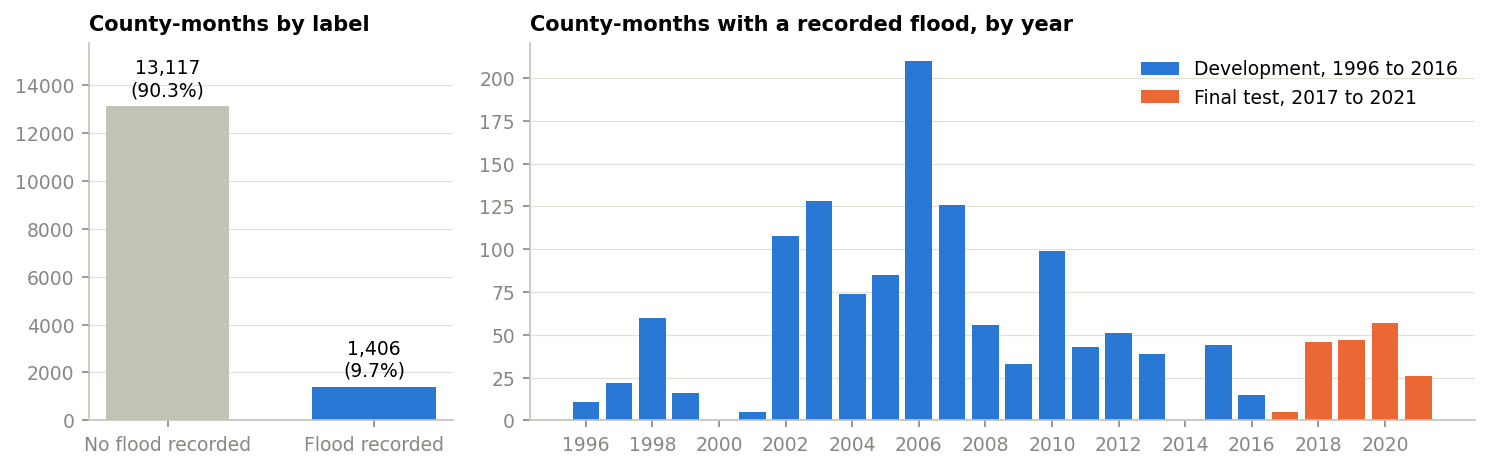

In [3]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, ".")
from riskengine.ml import train

MUTED, GRID, AXIS = "#898781", "#e1e0d9", "#c3c2b7"
COLOURS = {
    "logreg": "#2a78d6",
    "random-forest": "#eb6834",
    "gradient-boosting": "#1baf7a",
    "season-only": MUTED,
    "base-rate": AXIS,
}
LABELS = {
    "logreg": "Logistic Regression",
    "random-forest": "Random Forest",
    "gradient-boosting": "Gradient Boosting",
    "season-only": "Season only",
    "base-rate": "Base rate",
}
BANDS = ["Low", "Moderate", "High", "Very High"]
plt.rcParams.update({
    "figure.dpi": 150,
    "figure.facecolor": "white",
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": AXIS,
    "axes.axisbelow": True,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "legend.frameon": False,
})


def show(fig, name):
    """Save the chart in the run folder, then show it."""
    fig.savefig(RUN_DIR / "figures" / f"{name}.png", dpi=150)
    plt.show()


rows = pd.read_csv(TRAINING_SET, parse_dates=["date"])
rows = rows[rows["date"].dt.year >= train.FIRST_TRAINING_YEAR]
by_year = rows.groupby(rows["date"].dt.year)["flood"].sum()

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.2), gridspec_kw={"width_ratios": [1, 2.6]})

counts = [int((rows["flood"] == 0).sum()), int((rows["flood"] == 1).sum())]
bars = left.bar(["No flood recorded", "Flood recorded"], counts, color=[AXIS, COLOURS["logreg"]], width=0.6)
left.bar_label(bars, [f"{count:,}\n({count / len(rows):.1%})" for count in counts], padding=3)
left.set_ylim(0, max(counts) * 1.2)
left.set_title("County-months by label")
left.grid(axis="x", visible=False)

is_test = by_year.index >= train.FINAL_TEST_FROM
right.bar(by_year.index[~is_test], by_year[~is_test], color=COLOURS["logreg"], width=0.8,
          label=f"Development, {by_year.index.min()} to {train.FINAL_TEST_FROM - 1}")
right.bar(by_year.index[is_test], by_year[is_test], color=COLOURS["random-forest"], width=0.8,
          label=f"Final test, {train.FINAL_TEST_FROM} to {by_year.index.max()}")
right.set_xticks(by_year.index[::2])
right.set_title("County-months with a recorded flood, by year")
right.grid(axis="x", visible=False)
right.legend(loc="upper right")
fig.tight_layout()
show(fig, "01_data_overview")

## 4. Train

Compares Logistic Regression, Random Forest and Gradient Boosting, holding out whole years at a time, against two baselines: always guessing the base rate, and a model that knows only the month. Each model's settings are searched over a small grid with `GridSearchCV` on the same year folds, and the searched settings are used only where they beat the fixed ones on held-out years. Then the best model is refitted on all the data and its probabilities are calibrated if that helps on held-out years.

The whole procedure runs twice, once on every year and once on 1996 to 2016 for the final test, so this takes a while. The cross-validation is then repeated with five random seeds and at four sizes of training set, for the two sections after the fold scores.

Nothing is printed until it finishes: the output is collected so it can be saved as `log.txt` in the run folder, with how long the training took.

In [4]:
import contextlib
import io
import time

from geodata.services.climate_indices import fetch_dmi, fetch_oni
from riskengine.ml.pipeline import hazard, runs

log = io.StringIO()
started = time.perf_counter()
with contextlib.redirect_stdout(log):
    # Everything that decides the result comes from CONFIG; nothing is set here.
    result = hazard.run(CONFIG, fetch_oni(), fetch_dmi())
    data, chosen = result.data, result.chosen  # kept for the curves in step 5
    artifact, metrics = result.artifact, result.metrics
    runs.write(RUN_ID, CONFIG, artifact, metrics, RUNS_DIR)  # into RUN_DIR, never into artifacts/
    print(runs.record(RUN_ID, CONFIG, metrics, ledger=RUN_DIR / "ledger_line.md"))
    print("Trained", artifact["version"])
TRAIN_SECONDS = round(time.perf_counter() - started, 1)
print(f"Training took {TRAIN_SECONDS} seconds", file=log)
(RUN_DIR / "log.txt").write_text(log.getvalue())
print(log.getvalue(), end="")
print((RUN_DIR / "summary.md").read_text())

| 20261115T1309Z_55c0130_local | 2026-11-15 | hazard | `hazard_rf_era5_soil_20261115.toml` | random-forest | average_precision 0.266 | candidate |
Trained flood-random-forest-20261115
Training took 436.6 seconds
# Run 20261115T1309Z_55c0130_local

- Config: `hazard_rf_era5_soil_20261115.toml` (hazard)
- Commit: `55c0130e88d3a4a9c6ecc60130dd44af30bda16a`
- Training set SHA-256: `c0d26666fdb6e9b91bcc929beb58718d8b26855f635eb8c1963f9385d47c1d2f`
- Rows: 14523, positives: 1406
- Selected: random-forest, calibration: none
- average_precision on held-out years: 0.266
- Lift over the season-only model: 2.15

## Against the champion

flood-random-forest-20261007 scored 0.2535 on a different training set, so the two are not comparable. Score both on the same training set and folds before deciding anything.

Promotion also needs the guard metrics, a shadow period and a reviewed registry PR
(riskengine/ml/README.md). The final test is closed and was not scored.



## 5. How good is it?

All figures are on years the model did not see. **Average precision** is the one the winner is picked on. Compare it with both baselines: beating the base rate shows the model knows *something*; beating the season-only model shows rainfall, the ocean indices and terrain add something beyond "it is the rainy season". **Brier** is lower-is-better.

In [5]:
print(f"{metrics['rows']} county-months from {metrics['period'][0][:4]}, {metrics['positives']} with a recorded flood "
      f"(base rate {metrics['base_rate']:.1%}); rainfall: {metrics['rain_source']}")
print(f"Selected {metrics['selected']}: average precision {metrics['lift_over_base_rate']}x the base rate, "
      f"{metrics['lift_over_season_only']}x the season-only model. Calibration kept: {metrics['calibration']}")
comparison = pd.DataFrame(metrics["comparison"]).T
for name, scores in metrics["baselines"].items():
    comparison.loc[f"({name})"] = pd.Series(scores)
comparison

14523 county-months from 1996, 1406 with a recorded flood (base rate 9.7%); rainfall: open-meteo-point
Selected random-forest: average precision 2.75x the base rate, 2.15x the season-only model. Calibration kept: none


,roc_auc,average_precision,brier
logreg,0.7821,0.2588,0.0812
random-forest,0.7930,0.2660,0.0791
gradient-boosting,0.7667,0.2500,0.0800
(base-rate),0.5000,0.0968,0.0874
(season-only),0.5645,0.1235,0.0873


The same comparison as a chart. The grey bars are the two baselines.

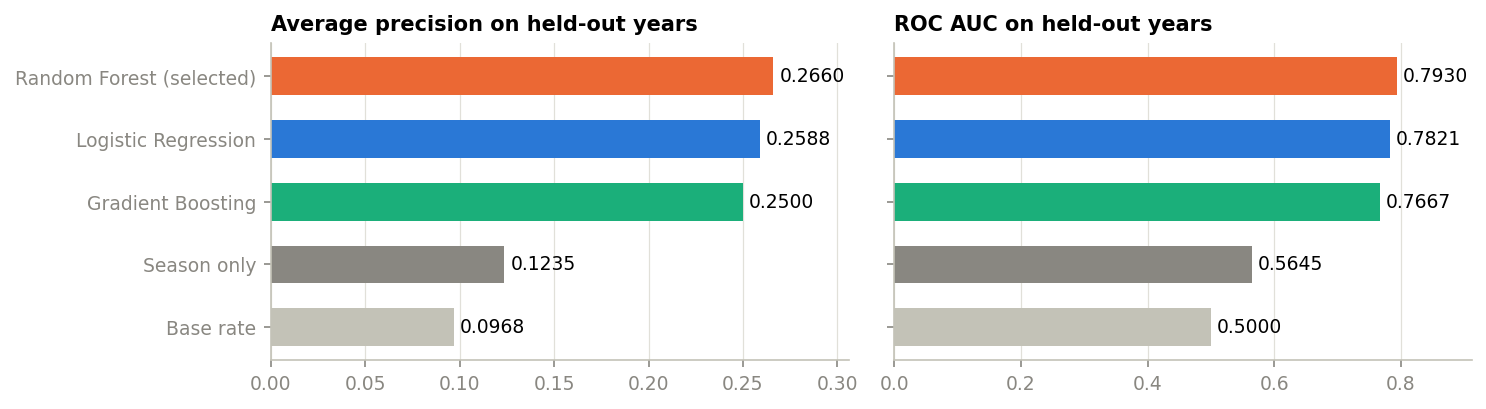

In [6]:
scores = {**metrics["comparison"], **metrics["baselines"]}
fig, axes = plt.subplots(1, 2, figsize=(10, 2.8), sharey=True)
for ax, (metric, title) in zip(axes, [("average_precision", "Average precision"), ("roc_auc", "ROC AUC")]):
    order = sorted(scores, key=lambda name: scores[name]["average_precision"])
    bars = ax.barh(
        [LABELS[name] + (" (selected)" if name == metrics["selected"] else "") for name in order],
        [scores[name][metric] for name in order],
        color=[COLOURS[name] for name in order],
        height=0.6,
    )
    ax.bar_label(bars, fmt="%.4f", padding=3)
    ax.set_xlim(0, max(scores[name][metric] for name in order) * 1.15)
    ax.set_title(f"{title} on held-out years")
    ax.grid(axis="y", visible=False)
fig.tight_layout()
show(fig, "02_model_comparison")

The settings search. `fixed` is each model at the settings written in `train.py`, `searched` at the settings `GridSearchCV` chose from the grid, both scored on held-out years with the county normals refitted per fold. `adopted` says whether the searched settings replaced the fixed ones. The same table for the final test's 1996 to 2016 is underneath: the search is repeated there without the test years.

In [7]:
def tuning_table(tuning):
    return pd.DataFrame({
        LABELS[name]: {
            "grid": record["grid"],
            "fixed settings": record["fixed_settings"],
            "searched settings": record["searched_settings"],
            "fixed AP": record["fixed"]["average_precision"],
            "searched AP": record["searched"]["average_precision"],
            "adopted": record["adopted"],
        }
        for name, record in tuning.items()
    }).T

with pd.option_context("display.max_colwidth", None):
    display(tuning_table(metrics["tuning"]))
    if metrics["final_test"]:  # None since the final test was closed
        display(tuning_table(metrics["final_test"]["tuning"]))

,grid,fixed settings,searched settings,fixed AP,searched AP,adopted
Logistic Regression,"{'C': ['0.01', '0.1', '1.0', '10.0']}",{'C': 1.0},{'C': 1.0},0.2588,0.2588,False
Random Forest,"{'min_samples_leaf': [5, 20, 50], 'max_features': ['sqrt', '0.5']}","{'max_features': 'sqrt', 'min_samples_leaf': 20}","{'max_features': 'sqrt', 'min_samples_leaf': 50}",0.266,0.2645,False
Gradient Boosting,"{'max_depth': [2, 3], 'learning_rate': ['0.02', '0.05', '0.1']}","{'learning_rate': 0.05, 'max_depth': 3}","{'learning_rate': 0.02, 'max_depth': 2}",0.2376,0.25,True


The curves behind those two numbers, from each row's probability under a model that never saw its year.

**ROC**: how many floods are caught against how many non-floods are wrongly flagged, as the warning threshold moves. The diagonal is guessing. **Precision-recall**: of the warnings given, how many were floods, against how many floods were caught. The dashed line is the base rate.

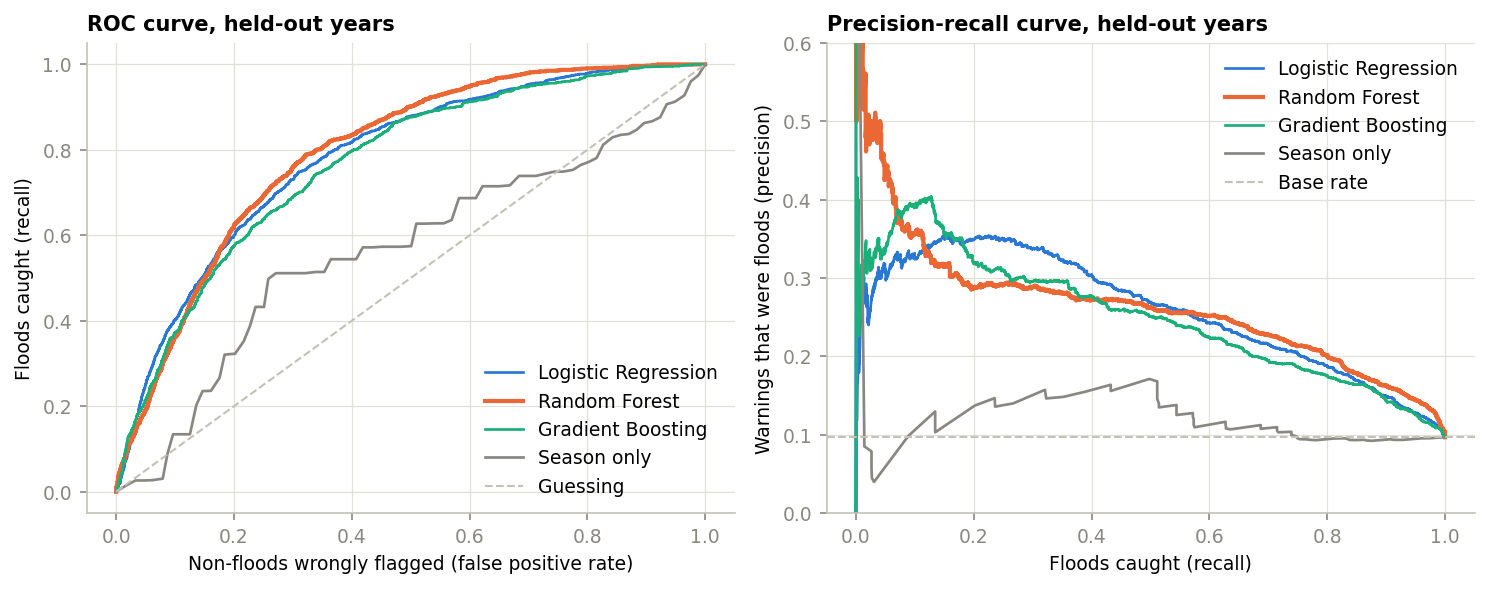

In [8]:
from sklearn.metrics import precision_recall_curve, roc_curve

held_out = {**chosen.held_out, "season-only": chosen.season}

fig, (roc, pr) = plt.subplots(1, 2, figsize=(10, 4))
for name, probabilities in held_out.items():
    style = {"color": COLOURS[name], "label": LABELS[name], "linewidth": 2 if name == chosen.best else 1.3}
    false_alarms, caught, _ = roc_curve(data.y, probabilities)
    roc.plot(false_alarms, caught, **style)
    precision, recall, _ = precision_recall_curve(data.y, probabilities)
    pr.plot(recall, precision, **style)
roc.plot([0, 1], [0, 1], color=AXIS, linestyle="--", linewidth=1, label="Guessing")
roc.set_xlabel("Non-floods wrongly flagged (false positive rate)")
roc.set_ylabel("Floods caught (recall)")
roc.set_title("ROC curve, held-out years")
roc.legend(loc="lower right")
pr.axhline(data.y.mean(), color=AXIS, linestyle="--", linewidth=1, label="Base rate")
pr.set_xlabel("Floods caught (recall)")
pr.set_ylabel("Warnings that were floods (precision)")
pr.set_ylim(0, 0.6)  # the first few rows jump to 1.0; the comparison is below that
pr.set_title("Precision-recall curve, held-out years")
pr.legend(loc="upper right")
fig.tight_layout()
show(fig, "03_roc_pr_curves")

How often a flood was actually recorded in each risk band, on held-out years, after calibration. The bands are only useful if this rises from Low to Very High, and `mean_predicted` should sit close to `observed_flood_rate`.

In [9]:
pd.DataFrame(metrics["band_calibration"]).set_index("band")

,rows,mean_predicted,observed_flood_rate
band,,,
low,6960,0.0198,0.0227
moderate,2838,0.0726,0.0761
high,2590,0.1418,0.1745
very_high,2135,0.3124,0.2717


Bars are the share of county-months in each band that had a recorded flood; the dot is what the model said on average. Left is cross-validation, right is the 2017 to 2021 final test. The bands are useful if the bars rise from Low to Very High, and trustworthy as probabilities only if the dots sit on top of the bars.

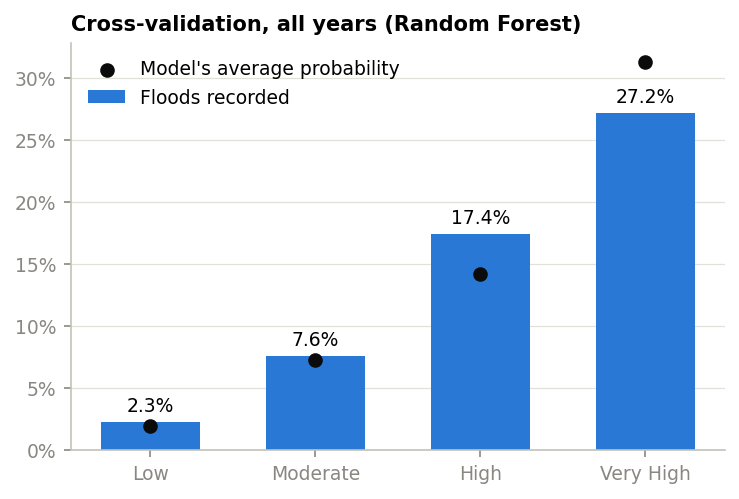

In [10]:
panels = [
    (f"Cross-validation, all years ({LABELS[metrics['selected']]})", metrics["band_calibration"]),
]
if metrics["final_test"]:  # None since the final test was closed
    panels.append(
        (f"Final test, 2017 to 2021 ({LABELS[metrics['final_test']['selected']]})", metrics["final_test"]["band_calibration"])
    )
fig, axes = plt.subplots(1, len(panels), figsize=(5 * len(panels), 3.4), sharey=True, squeeze=False)
axes = axes[0]
for ax, (title, bands) in zip(axes, panels):
    observed = [100 * (band["observed_flood_rate"] or 0) for band in bands]
    predicted = [100 * (band["mean_predicted"] or 0) for band in bands]
    bars = ax.bar(BANDS, observed, color=COLOURS["logreg"], width=0.6, label="Floods recorded")
    ax.bar_label(bars, fmt="%.1f%%", padding=3)
    ax.scatter(BANDS, predicted, color="#0b0b0b", s=36, zorder=3, label="Model's average probability")
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
    ax.yaxis.set_major_formatter("{x:.0f}%")
axes[0].legend(loc="upper left")
fig.tight_layout()
show(fig, "04_risk_bands")

Calibration on held-out years. ROC AUC barely moves (calibration does not change the ranking); the one with the lowest Brier is kept.

In [11]:
pd.DataFrame(metrics["calibration_comparison"]).T

,roc_auc,average_precision,brier
none,0.7930,0.2660,0.0791
sigmoid,0.7847,0.2546,0.0796
isotonic,0.7709,0.2229,0.0804


Average precision in each fold, with the years it held out. The pooled figures above hide how much the result depends on which years are held out; the spread here is the honest error bar.

In [12]:
folds = pd.DataFrame(
    {name: scores["average_precision"] for name, scores in fold["scores"].items()}
    | {"years": ", ".join(map(str, fold["years"])), "floods": fold["positives"]}
    for fold in metrics["folds"]
)
display(folds)
pd.DataFrame(metrics["fold_summary"]).T

,logreg,random-forest,gradient-boosting,season-only,years,floods
0,0.2661,0.2920,0.3351,0.2866,"1996, 2002, 2008, 2014, 2020",232
1,0.1605,0.1780,0.1437,0.0785,"2001, 2007, 2013, 2019, 2021",243
2,0.4639,0.3468,0.3322,0.2516,"2000, 2006, 2012, 2018",307
3,0.2205,0.1982,0.1350,0.0702,"1999, 2005, 2011, 2017",149
4,0.3435,0.3761,0.5671,0.3179,"1998, 2004, 2010, 2016",248
5,0.2400,0.4080,0.3132,0.2074,"1997, 2003, 2009, 2015",227


,average_precision_mean,average_precision_sd,roc_auc_mean,roc_auc_sd
logreg,0.2824,0.1072,0.7846,0.0568
random-forest,0.2998,0.0948,0.7999,0.0508
gradient-boosting,0.3044,0.1583,0.7756,0.0700
season-only,0.2020,0.1055,0.6049,0.1669


The same per-fold scores as a chart, and which years each fold holds out. A fold is always whole years, never a random sample of rows.

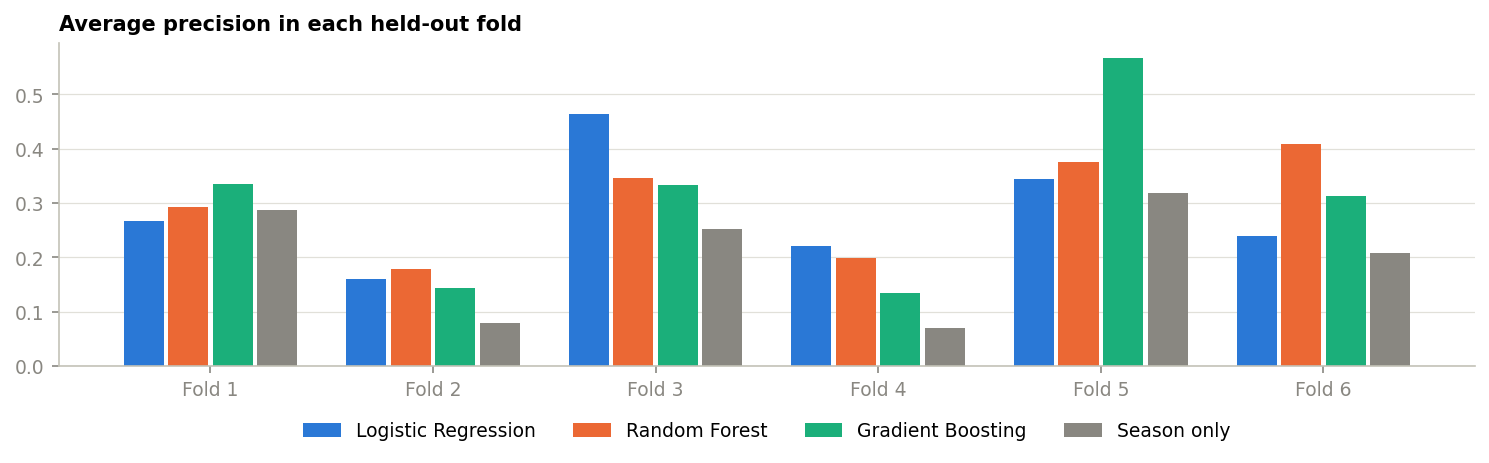

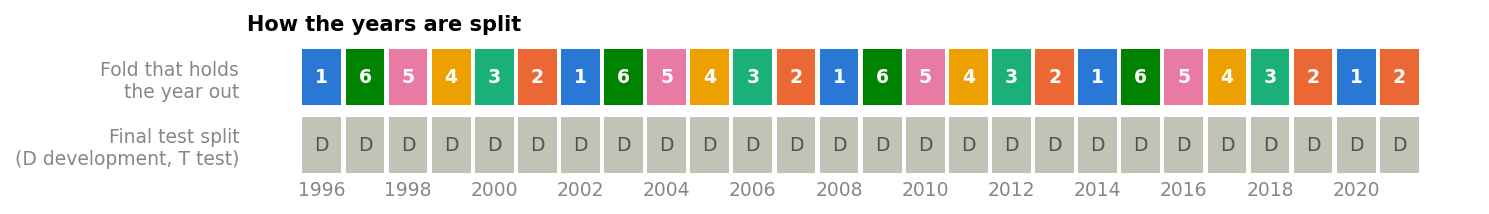

In [13]:
fold_names = [f"Fold {index + 1}" for index in range(len(metrics["folds"]))]
models = [*metrics["comparison"], "season-only"]
fig, ax = plt.subplots(figsize=(10, 3.2))
width = 0.8 / len(models)
for offset, name in enumerate(models):
    ax.bar(
        np.arange(len(fold_names)) + (offset - (len(models) - 1) / 2) * width,
        [fold["scores"][name]["average_precision"] or 0 for fold in metrics["folds"]],
        width=width * 0.9,
        color=COLOURS[name],
        label=LABELS[name],
    )
ax.set_xticks(np.arange(len(fold_names)), fold_names)
ax.set_title("Average precision in each held-out fold")
ax.grid(axis="x", visible=False)
ax.legend(ncols=len(models), loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig.tight_layout()
show(fig, "05_fold_scores")

FOLD_COLOURS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
fold_of = {year: index for index, fold in enumerate(metrics["folds"]) for year in fold["years"]}
years = sorted(fold_of)
fig, ax = plt.subplots(figsize=(10, 1.5))
for year in years:
    ax.bar(year, 1, bottom=1.2, width=0.9, color=FOLD_COLOURS[fold_of[year] % len(FOLD_COLOURS)])
    ax.text(year, 1.7, str(fold_of[year] + 1), ha="center", va="center", color="white", fontweight="bold")
    final = bool(metrics["final_test"]) and year >= metrics["final_test"]["test_from"]  # None since the test was closed
    ax.bar(year, 1, bottom=0, width=0.9, color=COLOURS["random-forest"] if final else AXIS)
    ax.text(year, 0.5, "T" if final else "D", ha="center", va="center", color="white" if final else "#52514e")
ax.set_xticks(years[::2])
ax.set_yticks([0.5, 1.7], ["Final test split\n(D development, T test)", "Fold that holds\nthe year out"])
ax.tick_params(length=0)
ax.grid(visible=False)
ax.spines[["left", "bottom"]].set_visible(False)
ax.set_title("How the years are split")
fig.tight_layout()
show(fig, "06_year_split")

Repeated runs. The Random Forest and Gradient Boosting draw random numbers, so the same data gives slightly different scores under a different seed. Each was cross-validated again under five seeds, on the same folds and at the settings kept above. Logistic Regression has nothing random in it. If the gap between two models is smaller than this spread, the ranking between them is not settled. The saved model is seed 0.

In [14]:
variation = metrics["seed_variation"]
print("Seeds:", variation["seeds"])
pd.DataFrame({
    LABELS[name]: (
        {"note": record["note"]} if "note" in record else {
            "average precision, mean": record["average_precision"]["mean"],
            "average precision, sd": record["average_precision"]["sd"],
            "average precision, each seed": record["average_precision"]["values"],
            "ROC AUC, mean": record["roc_auc"]["mean"],
            "ROC AUC, sd": record["roc_auc"]["sd"],
        }
    )
    for name, record in variation.items() if name != "seeds"
}).T.fillna("")

Seeds: [0, 1, 2, 3, 4]


,note,"average precision, mean","average precision, sd","average precision, each seed","ROC AUC, mean","ROC AUC, sd"
Logistic Regression,deterministic,,,,,
Random Forest,,0.2679,0.0025,"[0.266, 0.2661, 0.2664, 0.2716, 0.2694]",0.7936,0.0021
Gradient Boosting,,0.2543,0.0049,"[0.25, 0.2619, 0.254, 0.2557, 0.2501]",0.7673,0.0029


The learning curve. In each fold the selected model was fitted on a quarter, a half, three quarters and all of the training years, sampled as whole years, and scored on the same held-out years each time. The line is the mean over the six folds and the band is one standard deviation. A line still rising at the right-hand end says more recorded years would help; a flat one says the inputs or the labels are the limit.

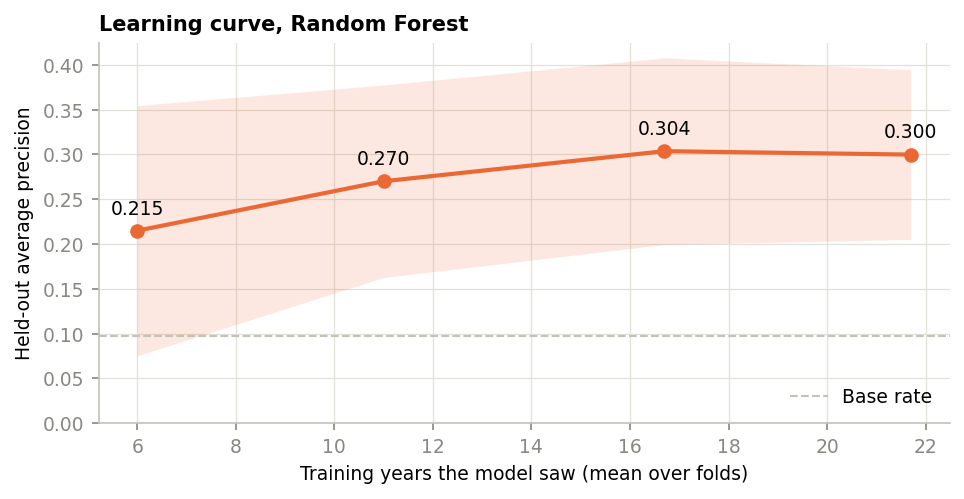

,fraction,folds,training_years_mean,training_rows_mean,average_precision_mean,average_precision_sd
0,0.25,6,6.0,3314,0.2149,0.1397
1,0.50,6,11.0,6134,0.2701,0.1075
2,0.75,6,16.7,9306,0.3037,0.1042
3,1.00,6,21.7,12102,0.2999,0.0948


In [15]:
curve = pd.DataFrame(metrics["learning_curve"])
fig, ax = plt.subplots(figsize=(6.5, 3.4))
colour = COLOURS[metrics["selected"]]
ax.fill_between(
    curve["training_years_mean"],
    curve["average_precision_mean"] - curve["average_precision_sd"],
    curve["average_precision_mean"] + curve["average_precision_sd"],
    color=colour, alpha=0.15, linewidth=0,
)
ax.plot(curve["training_years_mean"], curve["average_precision_mean"], color=colour, linewidth=2, marker="o")
for _, point in curve.iterrows():
    ax.annotate(f"{point['average_precision_mean']:.3f}", (point["training_years_mean"], point["average_precision_mean"]),
                textcoords="offset points", xytext=(0, 8), ha="center")
ax.axhline(metrics["base_rate"], color=AXIS, linestyle="--", linewidth=1, label="Base rate")
ax.set_ylim(0, None)
ax.set_xlabel("Training years the model saw (mean over folds)")
ax.set_ylabel("Held-out average precision")
ax.set_title(f"Learning curve, {LABELS[metrics['selected']]}")
ax.legend(loc="lower right")
fig.tight_layout()
show(fig, "11_learning_curve")
curve

What the run cost: seconds spent in each stage, and the machine it ran on.

In [16]:
pd.Series(metrics["compute"], name="value").to_frame()

,value
seconds_cross_validation,206.7
seconds_final_fit,1.8
seconds_permutation_importance,67.1
seconds_seed_variation,124.5
seconds_learning_curve,33.2
seconds_final_test,0.0
cpu,11th Gen Intel(R) Core(TM) i7-1185G7 @ 3.00GHz
cores,8


What happens if a probability above each band edge is treated as a warning. A false negative is a recorded flood with no warning.

In [17]:
pd.DataFrame(metrics["threshold_errors"]).set_index("threshold")

,true_positives,false_positives,false_negatives,true_negatives,precision,recall,specificity,accuracy,f1,balanced_accuracy,support_positive,support_negative
threshold,,,,,,,,,,,,
0.05,1248,6315,158,6802,0.1650,0.8876,0.5186,0.5543,0.2783,0.7031,1406,13117
0.10,1032,3693,374,9424,0.2184,0.7340,0.7185,0.7200,0.3366,0.7262,1406,13117
0.20,580,1555,826,11562,0.2717,0.4125,0.8815,0.8361,0.3276,0.6470,1406,13117


The 10% row of that table as a confusion matrix: a High or Very High band counts as a warning.

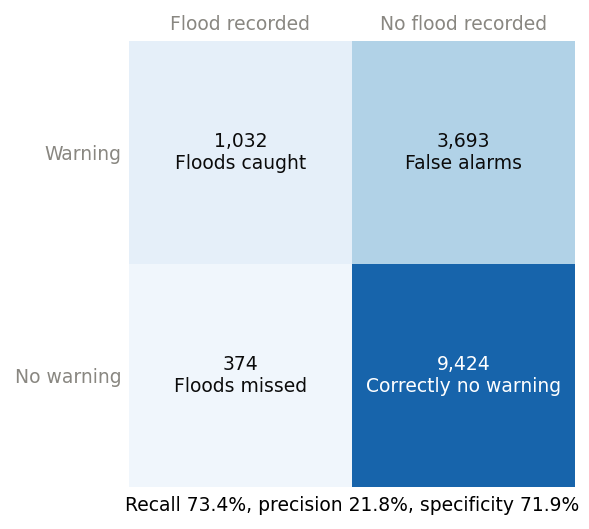

In [18]:
errors = next(row for row in metrics["threshold_errors"] if row["threshold"] == 0.10)
matrix = np.array([
    [errors["true_positives"], errors["false_positives"]],
    [errors["false_negatives"], errors["true_negatives"]],
])
names = [["Floods caught", "False alarms"], ["Floods missed", "Correctly no warning"]]
fig, ax = plt.subplots(figsize=(5.2, 3.6))
ax.imshow(matrix, cmap="Blues", vmin=0, vmax=matrix.max() * 1.25)
for row in range(2):
    for column in range(2):
        ax.text(
            column, row, f"{matrix[row, column]:,}\n{names[row][column]}",
            ha="center", va="center",
            color="white" if matrix[row, column] > matrix.max() * 0.6 else "#0b0b0b",
        )
ax.set_xticks([0, 1], ["Flood recorded", "No flood recorded"])
ax.set_yticks([0, 1], ["Warning", "No warning"])
ax.xaxis.tick_top()
ax.tick_params(length=0)
ax.grid(visible=False)
ax.spines[:].set_visible(False)
ax.set_xlabel(
    f"Recall {errors['recall']:.1%}, precision {errors['precision']:.1%}, specificity {errors['specificity']:.1%}"
)
fig.tight_layout()
show(fig, "07_confusion_matrix")

Where those errors fall. Left: recorded floods in each calendar month, split into caught and missed. Right: the fifteen counties with the most recorded floods, split the same way.

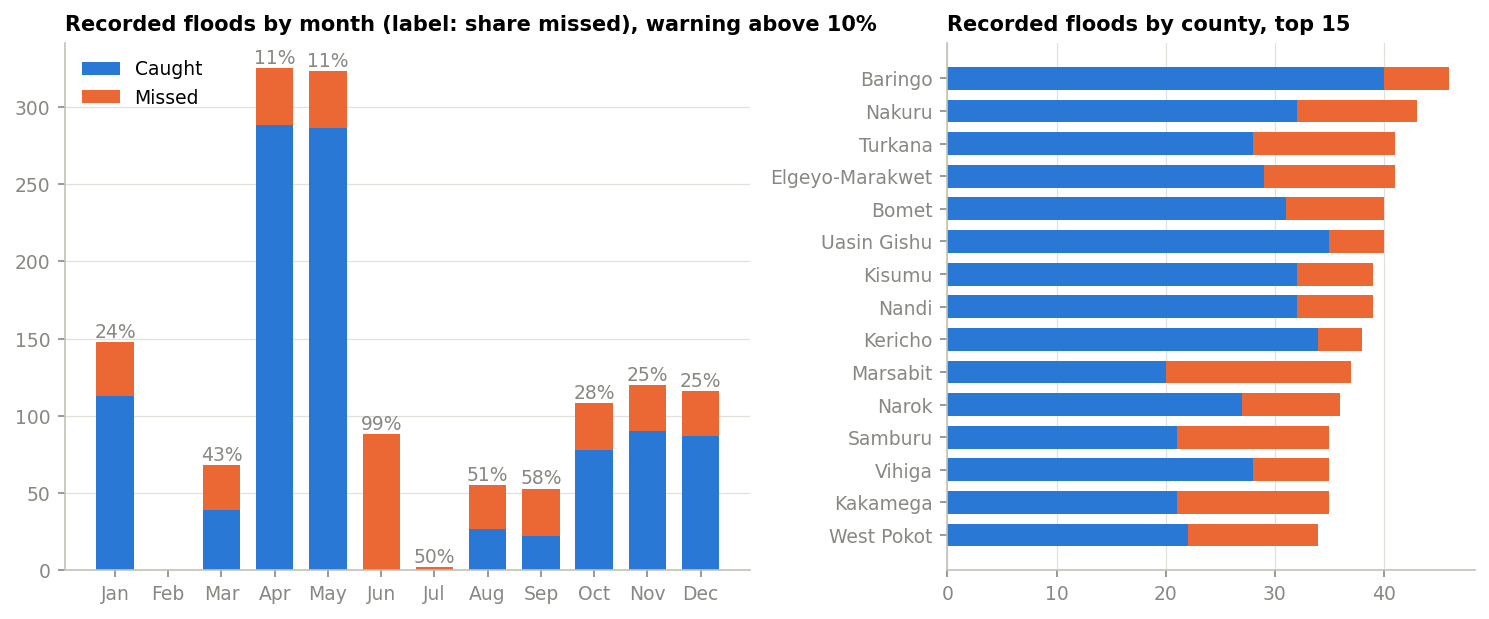

False alarms by month: {'Jan': 256, 'Feb': 118, 'Mar': 281, 'Apr': 657, 'May': 585, 'Jun': 241, 'Jul': 51, 'Aug': 112, 'Sep': 189, 'Oct': 396, 'Nov': 424, 'Dec': 383}


In [19]:
breakdown = metrics["error_breakdown"]
months = pd.DataFrame(breakdown["by_month"]).set_index("month")
counties = pd.DataFrame(breakdown["by_county"]).set_index("county").sort_values("floods").tail(15)
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 4.2), gridspec_kw={"width_ratios": [1.3, 1]})
left.bar(MONTHS, months["caught"], color=COLOURS["logreg"], width=0.7, label="Caught")
left.bar(MONTHS, months["missed"], bottom=months["caught"], color=COLOURS["random-forest"], width=0.7, label="Missed")
for position, (caught, missed) in enumerate(zip(months["caught"], months["missed"])):
    if caught + missed:
        left.text(position, caught + missed + 3, f"{missed / (caught + missed):.0%}", ha="center", color=MUTED)
left.set_title(f"Recorded floods by month (label: share missed), warning above {breakdown['threshold']:.0%}")
left.grid(axis="x", visible=False)
left.legend(loc="upper left")
right.barh(counties.index, counties["caught"], color=COLOURS["logreg"], height=0.7)
right.barh(counties.index, counties["missed"], left=counties["caught"], color=COLOURS["random-forest"], height=0.7)
right.set_title("Recorded floods by county, top 15")
right.grid(axis="y", visible=False)
fig.tight_layout()
show(fig, "08_error_breakdown")

print("False alarms by month:", dict(zip(MONTHS, months["false_alarms"])))

The final test. The years from 2017 on were set aside, the model and calibration were chosen again on 1996 to 2016 alone, and 2017 to 2021 were scored. That test was looked at about seven times and was **closed on 29 October 2026**: no run scores it again (`riskengine/ml/experiments.md`). Its last result, for the served model, is in `riskengine/ml/artifacts/metrics.json`. Real-world performance is now measured on each new season, once, as it arrives.

In [20]:
test = metrics["final_test"]
if test is None:
    print("Final test closed: not scored.")
else:
    print(f"{test['rows']} county-months, {test['positives']} floods, {test['test_years']}")
    display(pd.DataFrame(
        {f"{test['selected']} (chosen)": test["scores"]} | test["other_candidates"] | test["baselines"]
    ).T)
    display(pd.DataFrame(test["band_calibration"]).set_index("band"))

Final test closed: not scored.


The commit, run, data and seed this result came from, as stored in `metrics.json`. `git_commit` is the repository's commit when this notebook ran.

In [21]:
assert metrics["provenance"]["git_commit"] == COMMIT
assert metrics["provenance"]["training_set_sha256"] == DATASET_SHA256
metrics["provenance"]

{'git_commit': '55c0130e88d3a4a9c6ecc60130dd44af30bda16a',
 'run_id': '20261115T1309Z_55c0130_local',
 'training_set_sha256': 'c0d26666fdb6e9b91bcc929beb58718d8b26855f635eb8c1963f9385d47c1d2f',
 'random_state': 0,
 'scikit_learn': '1.9.1'}

What the model leans on. Each input is shuffled in turn on the held-out years, and the bar is how far average precision falls, averaged over the six folds (the line is one standard deviation across folds). An input the model does not need scores about zero. Inputs that carry the same information share the credit: shuffling `rain_30d` leaves `rain_30d_ratio` intact. `log_area` is a control for how the labels are made, not a cause of flooding; see `riskengine/ml/README.md`.

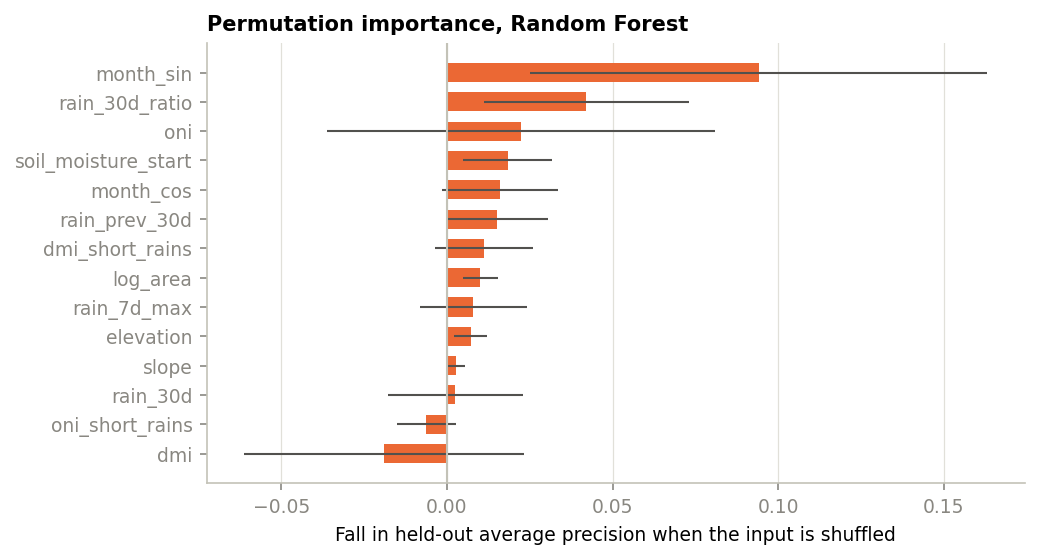

In [22]:
importance = pd.DataFrame(metrics["permutation_importance"]).T.sort_values("mean")
fig, ax = plt.subplots(figsize=(7, 3.8))
bars = ax.barh(importance.index, importance["mean"], xerr=importance["sd"], color=COLOURS[metrics["selected"]],
               height=0.65, error_kw={"ecolor": "#52514e", "elinewidth": 1})
ax.axvline(0, color=AXIS, linewidth=1)
ax.set_title(f"Permutation importance, {LABELS[metrics['selected']]}")
ax.set_xlabel("Fall in held-out average precision when the input is shuffled")
ax.grid(axis="y", visible=False)
fig.tight_layout()
show(fig, "09_permutation_importance")

In which direction. Partial dependence of the saved model on its four most important inputs: the average predicted probability as one input is moved across its range and the others are left as recorded. The ticks along the bottom show where the data is.

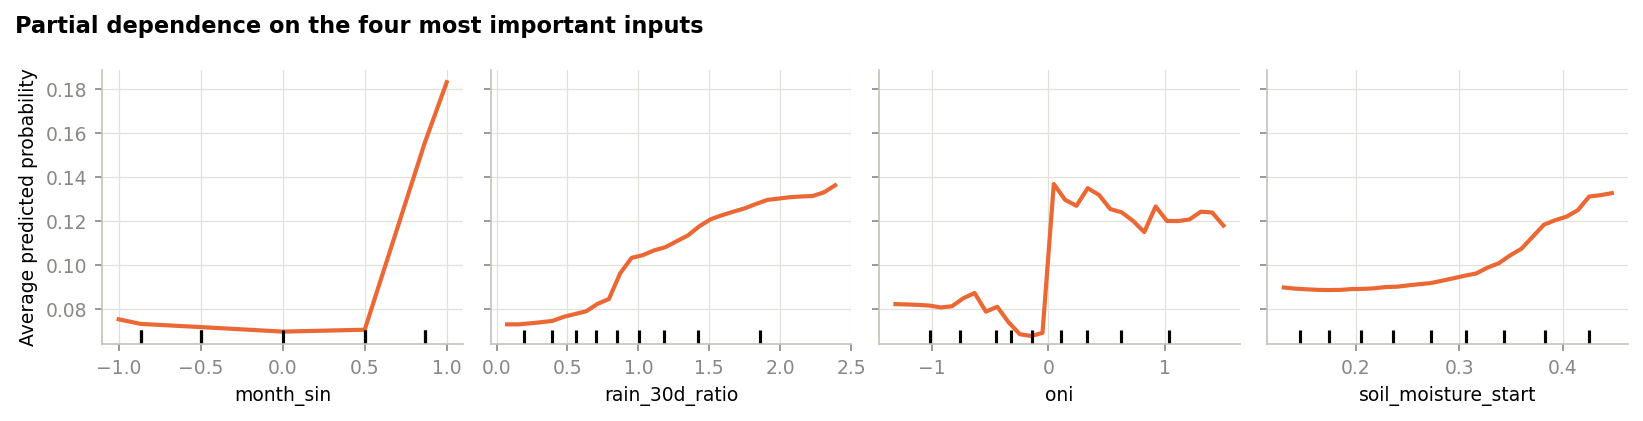

In [23]:
from sklearn.inspection import PartialDependenceDisplay

model = getattr(artifact["pipeline"], "pipeline", artifact["pipeline"])  # under any calibration
top = list(importance.index[::-1][:4])
fig, axes = plt.subplots(1, 4, figsize=(11, 2.8), sharey=True)
PartialDependenceDisplay.from_estimator(
    model,
    train.with_normals(data, artifact["normals"]),
    [artifact["features"].index(name) for name in top],
    feature_names=artifact["features"],
    grid_resolution=30,
    ax=axes,
    line_kw={"color": COLOURS[metrics["selected"]], "linewidth": 2},
)
for ax in axes:
    ax.set_ylabel("")
axes[0].set_ylabel("Average predicted probability")
fig.suptitle("Partial dependence on the four most important inputs", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
show(fig, "10_partial_dependence")

What pushes the probability up or down (logistic regression only). Coefficients are per standard deviation of each input, so they can be compared with each other. `log_area` is a control for how the labels are made, not a cause of flooding; see `riskengine/ml/README.md`.

In [24]:
pd.Series(metrics.get("standardised_coefficients", {}), name="coefficient").sort_values().to_frame()

,coefficient


## 6. Save the run

The model, its metrics, the config, the summary and the ledger line were written into the run's folder by step 4. This adds the installed packages and a short record of the run. The model file stays out of git (`.gitignore`); the rest is committed.

In [25]:
import platform
import sys

(RUN_DIR / "environment.txt").write_text(
    subprocess.run([sys.executable, "-m", "pip", "freeze"], capture_output=True, text=True).stdout
)
(RUN_DIR / "run.json").write_text(json.dumps({
    "run_id": RUN_ID,
    "commit": COMMIT,
    "bundle": None,  # local rehearsal, no bundle
    "config": str(CONFIG.path),
    "training_set_sha256": DATASET_SHA256,
    "model_version": artifact["version"],
    "python": platform.python_version(),
    "machine": platform.processor() or platform.machine(),
    "cores": os.cpu_count(),
    "seconds": TRAIN_SECONDS,
}, indent=2) + "\n")
print("Saved to", RUN_DIR)

Saved to /app/riskengine/ml/runs/20261115T1309Z_55c0130_local
